In [ ]:
import tensorflow as tf
import os
import sys
print("python:", sys.version.split()[0])
print("tensorflow:", tf.__version__)
print("keras:", tf.keras.__version__)

url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
path = tf.keras.utils.get_file("flower_photos", url, untar=True)

# arahkan ke folder yang berisi subfolder kelas
data_dir = path
if not os.path.isdir(os.path.join(path, "daisy")):
    data_dir = os.path.join(path, "flower_photos")
print("Folder data:", data_dir, os.listdir(data_dir))

train = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=42,
    image_size=(224, 224), batch_size=32)
val = tf.keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=(224, 224), batch_size=32)

kelas = train.class_names
print(kelas)


python: 3.13.15
tensorflow: 2.21.0
keras: 3.13.2
228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step


In [ ]:
from tensorflow.keras import layers, models

base = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False

model = models.Sequential([
    layers.Input((224, 224, 3)),
    layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(kelas), activation="softmax"),
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(train, validation_data=val, epochs=5)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 34s 212ms/step - accuracy: 0.7548 - loss: 0.7544 - val_accuracy: 0.8597 - val_loss: 0.4105
Epoch 2/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.8753 - loss: 0.3470 - val_accuracy: 0.8842 - val_loss: 0.3416
Epoch 3/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 6s 60ms/step - accuracy: 0.8954 - loss: 0.2793 - val_accuracy: 0.8801 - val_loss: 0.3411
Epoch 4/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 10s 63ms/step - accuracy: 0.9172 - loss: 0.2172 - val_accuracy: 0.8842 - val_loss: 0.3550
Epoch 5/5
92/92 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.9305 - loss: 0.1934 - val_accuracy: 0.8951 - val_loss: 0.3244


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import pandas as pd

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train.prefetch(AUTOTUNE)
val_ds = val.prefetch(AUTOTUNE)

augment = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

def buat_model(lr=1e-3, dropout=0.3, units=128):
    base = tf.keras.applications.MobileNetV2(
        input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    m = models.Sequential([
        layers.Input((224, 224, 3)),
        augment,  # hanya aktif saat training
        layers.Lambda(tf.keras.applications.mobilenet_v2.preprocess_input),
        base,
        layers.GlobalAveragePooling2D(),
        layers.BatchNormalization(),
        layers.Dropout(dropout),
        layers.Dense(units, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(len(kelas), activation="softmax"),
    ])
    m.compile(optimizer=tf.keras.optimizers.Adam(lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m, base


In [ ]:
konfigurasi = [
    {"lr": 1e-3, "dropout": 0.3, "units": 128},   # baseline
    {"lr": 1e-4, "dropout": 0.3, "units": 128},
    {"lr": 3e-4, "dropout": 0.3, "units": 128},
    {"lr": 1e-3, "dropout": 0.5, "units": 128},
    {"lr": 1e-4, "dropout": 0.5, "units": 128},
    {"lr": 1e-3, "dropout": 0.3, "units": 256},
    {"lr": 3e-4, "dropout": 0.5, "units": 256},
    {"lr": 1e-4, "dropout": 0.3, "units": 256},
]

tf.keras.utils.set_random_seed(42)
hasil = []
terbaik = None
for cfg in konfigurasi:
    print("Mencoba:", cfg)
    m, b = buat_model(**cfg)
    h = m.fit(train_ds, validation_data=val_ds, epochs=5, verbose=2)
    va = max(h.history["val_accuracy"])
    hasil.append({**cfg,
                  "train_acc": h.history["accuracy"][-1],
                  "val_acc": va,
                  "val_loss": min(h.history["val_loss"])})
    if terbaik is None or va > terbaik[0]:
        terbaik = (va, cfg)
    tf.keras.backend.clear_session()  # jaga RAM Colab

tabel = pd.DataFrame(hasil).sort_values("val_acc", ascending=False)
print(tabel)          # <- screenshot / salin ke laporan
print("Konfigurasi terbaik:", terbaik[1])


Mencoba: {'lr': 0.001, 'dropout': 0.3, 'units': 128}
Epoch 1/5
92/92 - 18s - 191ms/step - accuracy: 0.7285 - loss: 0.8574 - val_accuracy: 0.8774 - val_loss: 0.3591
Epoch 2/5
92/92 - 7s - 71ms/step - accuracy: 0.8478 - loss: 0.4421 - val_accuracy: 0.8774 - val_loss: 0.3546
Epoch 3/5
92/92 - 6s - 70ms/step - accuracy: 0.8689 - loss: 0.3691 - val_accuracy: 0.8747 - val_loss: 0.3824
Epoch 4/5
92/92 - 6s - 70ms/step - accuracy: 0.8774 - loss: 0.3379 - val_accuracy: 0.8828 - val_loss: 0.3622
Epoch 5/5
92/92 - 7s - 71ms/step - accuracy: 0.8903 - loss: 0.2868 - val_accuracy: 0.8801 - val_loss: 0.3623
Mencoba: {'lr': 0.0001, 'dropout': 0.3, 'units': 128}
Epoch 1/5
92/92 - 13s - 139ms/step - accuracy: 0.4598 - loss: 1.6831 - val_accuracy: 0.7262 - val_loss: 0.8298
Epoch 2/5
92/92 - 9s - 97ms/step - accuracy: 0.6693 - loss: 0.9898 - val_accuracy: 0.8093 - val_loss: 0.5779
Epoch 3/5
92/92 - 10s - 111ms/step - accuracy: 0.7381 - loss: 0.7729 - val_accuracy: 0.8297 - val_loss: 0.4842
Epoch 4/5
92/92

In [ ]:
if "model_baseline" not in globals():
    model_baseline = model  # simpan baseline, jangan timpa saat run ulang

tf.keras.utils.set_random_seed(42)
model, base = buat_model(**terbaik[1])  # model HASIL TUNING

cb = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]
h1 = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=cb, verbose=2)

# Fine-tuning: buka 30 layer teratas MobileNetV2 (BatchNorm tetap beku)
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=6, callbacks=cb, verbose=2)


Epoch 1/8
92/92 - 13s - 141ms/step - accuracy: 0.7251 - loss: 0.8222 - val_accuracy: 0.8692 - val_loss: 0.4017 - learning_rate: 0.0010
Epoch 2/8
92/92 - 8s - 84ms/step - accuracy: 0.8488 - loss: 0.4490 - val_accuracy: 0.8815 - val_loss: 0.3607 - learning_rate: 0.0010
Epoch 3/8
92/92 - 7s - 71ms/step - accuracy: 0.8648 - loss: 0.3838 - val_accuracy: 0.8910 - val_loss: 0.3368 - learning_rate: 0.0010
Epoch 4/8
92/92 - 6s - 70ms/step - accuracy: 0.8811 - loss: 0.3343 - val_accuracy: 0.8747 - val_loss: 0.3552 - learning_rate: 0.0010
Epoch 5/8
92/92 - 6s - 70ms/step - accuracy: 0.8954 - loss: 0.2935 - val_accuracy: 0.8883 - val_loss: 0.3486 - learning_rate: 0.0010
Epoch 6/8
92/92 - 10s - 111ms/step - accuracy: 0.9067 - loss: 0.2486 - val_accuracy: 0.8883 - val_loss: 0.3485 - learning_rate: 5.0000e-04
Epoch 1/6
92/92 - 14s - 157ms/step - accuracy: 0.8825 - loss: 0.3192 - val_accuracy: 0.8978 - val_loss: 0.3309 - learning_rate: 1.0000e-05
Epoch 2/6
92/92 - 10s - 111ms/step - accuracy: 0.8992 -

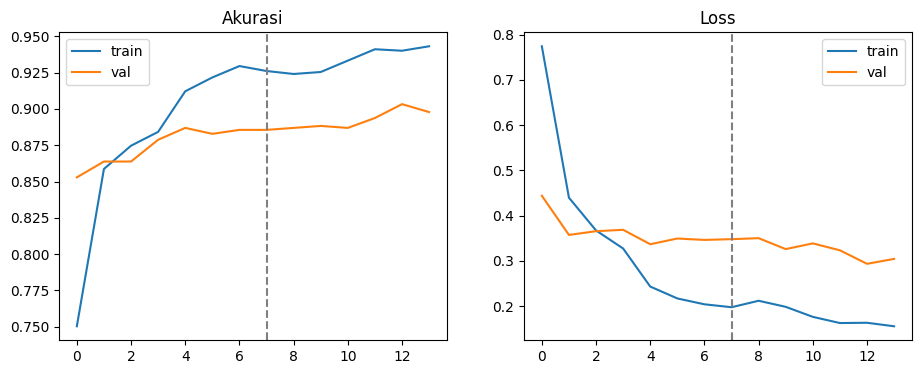

              precision    recall  f1-score   support

       daisy     0.8783    0.9439    0.9099       107
   dandelion     0.9778    0.9215    0.9488       191
       roses     0.8120    0.9076    0.8571       119
  sunflowers     0.9098    0.8963    0.9030       135
      tulips     0.9075    0.8626    0.8845       182

    accuracy                         0.9033       734
   macro avg     0.8971    0.9064    0.9007       734
weighted avg     0.9065    0.9033    0.9039       734



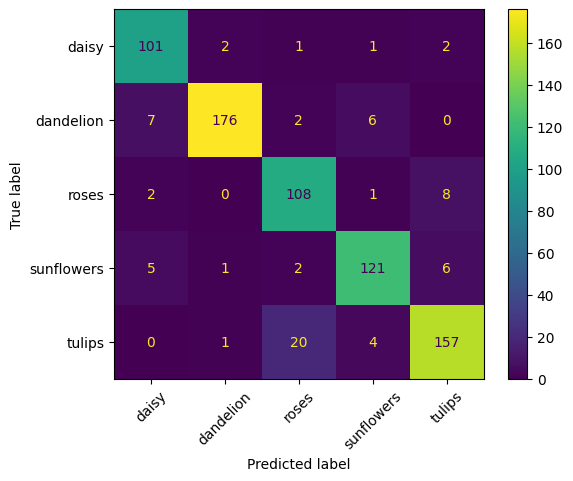

=== BASELINE (sebelum tuning) ===
              precision    recall  f1-score   support

       daisy     0.8417    0.9439    0.8899       107
   dandelion     0.9309    0.9162    0.9235       191
       roses     0.8217    0.8908    0.8548       119
  sunflowers     0.9051    0.9185    0.9118       135
      tulips     0.9437    0.8297    0.8830       182

    accuracy                         0.8951       734
   macro avg     0.8886    0.8998    0.8926       734
weighted avg     0.8986    0.8951    0.8953       734



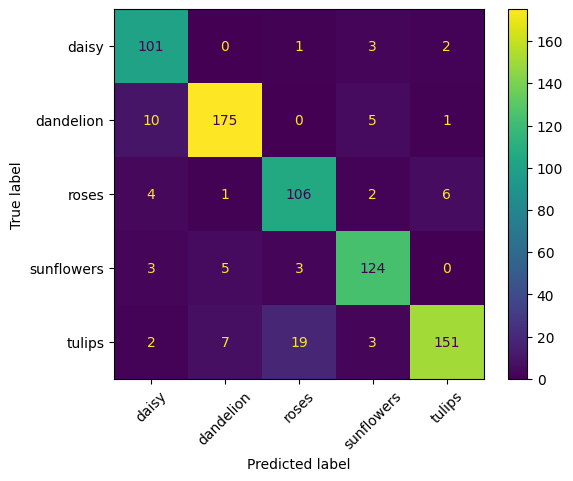

                  model  val_acc  macro_f1  val_loss
0              Baseline   0.8951    0.8926    0.3244
1  Tuning + fine-tuning   0.9033    0.9007    0.2936


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# kurva akurasi & loss (gabungan tahap 1 + fine-tuning)
acc = h1.history["accuracy"] + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
los = h1.history["loss"] + h2.history["loss"]
vlos = h1.history["val_loss"] + h2.history["val_loss"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(acc, label="train"); ax[0].plot(vacc, label="val")
ax[0].axvline(len(h1.history["accuracy"]) - 1, ls="--", c="gray")
ax[0].set_title("Akurasi"); ax[0].legend()
ax[1].plot(los, label="train"); ax[1].plot(vlos, label="val")
ax[1].axvline(len(h1.history["loss"]) - 1, ls="--", c="gray")
ax[1].set_title("Loss"); ax[1].legend()
plt.savefig("kurva_training.png", dpi=150, bbox_inches="tight")
plt.show()

# prediksi dan label diambil dalam satu lintasan (val di-shuffle)
y_true, y_pred = [], []
for xb, yb in val:
    p = model.predict(xb, verbose=0)
    y_true.extend(yb.numpy()); y_pred.extend(np.argmax(p, axis=1))

print(classification_report(y_true, y_pred, target_names=kelas, digits=4))
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=kelas).plot(xticks_rotation=45)
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()


# ---- perbandingan: evaluasi BASELINE dengan cara yang sama ----
yb_true, yb_pred = [], []
for xb, yb in val:
    p = model_baseline.predict(xb, verbose=0)
    yb_true.extend(yb.numpy()); yb_pred.extend(np.argmax(p, axis=1))

print("=== BASELINE (sebelum tuning) ===")
print(classification_report(yb_true, yb_pred, target_names=kelas, digits=4))
ConfusionMatrixDisplay(confusion_matrix(yb_true, yb_pred), display_labels=kelas).plot(xticks_rotation=45)
plt.savefig("confusion_matrix_baseline.png", dpi=150, bbox_inches="tight")
plt.show()


# ---- tabel ringkas SEBELUM vs SESUDAH ----
from sklearn.metrics import accuracy_score, f1_score
loss_b, _ = model_baseline.evaluate(val, verbose=0)
loss_f, _ = model.evaluate(val, verbose=0)
ringkas = pd.DataFrame([
    {"model": "Baseline", "val_acc": accuracy_score(yb_true, yb_pred),
     "macro_f1": f1_score(yb_true, yb_pred, average="macro"), "val_loss": loss_b},
    {"model": "Tuning + fine-tuning", "val_acc": accuracy_score(y_true, y_pred),
     "macro_f1": f1_score(y_true, y_pred, average="macro"), "val_loss": loss_f},
])
print(ringkas.round(4))  # <- screenshot untuk laporan


In [ ]:
model.save("model_cnn.keras")
import json
with open("kelas.json", "w") as f:
    json.dump(list(kelas), f)
print("tersimpan:", list(kelas))
from google.colab import files
files.download("model_cnn.keras")
files.download("kelas.json")
files.download("kurva_training.png")
files.download("confusion_matrix.png")
files.download("confusion_matrix_baseline.png")


tersimpan: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
# UJI GAMBAR BARU (di luar flower_photos).
# Upload dulu file-file gambar ke folder "Contoh_Sample_Gambar_Bunga" (Files > New folder),
# nama file format: <kelas>_<n>.jpg (mis. roses_1.jpg). Untuk uji OOD pakai
# prefix "ood", mis. ood_anggrek_1.jpg -> dicek vs ambang Unidentified 0.75.
import os, glob
import numpy as np
from PIL import Image, ImageOps

FOLDER_BARU = "Contoh_Sample_Gambar_Bunga"
TH = 0.75
files_baru = sorted(glob.glob(os.path.join(FOLDER_BARU, "*")))
print(f"jumlah gambar baru: {len(files_baru)}")
assert len(files_baru) > 0, "folder Contoh_Sample_Gambar_Bunga kosong! upload gambar dulu."

baris = []
for fp in files_baru:
    nama = os.path.basename(fp)
    prefix = nama.split("_")[0].lower()
    img = ImageOps.exif_transpose(Image.open(fp)).convert("RGB").resize((224, 224))
    x = np.expand_dims(np.array(img), axis=0).astype("float32")
    p = model.predict(x, verbose=0)[0]
    idx, conf = int(np.argmax(p)), float(max(p))
    if prefix == "ood":
        hasil = "Unidentified (sesuai harapan)" if conf < TH else f"TIDAK TERDETEKSI (diprediksi {kelas[idx]})"
        baris.append((nama, "di-luar-dataset", kelas[idx], round(conf * 100, 2), hasil))
    else:
        benar = kelas[idx].lower() == prefix
        baris.append((nama, prefix, kelas[idx], round(conf * 100, 2), "BENAR" if benar else "SALAH"))

import pandas as pd
tabel_baru = pd.DataFrame(baris, columns=["file", "label_asli", "prediksi", "confidence_%", "hasil"])
print(tabel_baru.to_string(index=False))
print(f"\nakurasi gambar baru (non-OOD): "
      f"{(tabel_baru[tabel_baru.file.str.split('_').str[0] != 'ood']['hasil'] == 'BENAR').mean() * 100:.2f}%")
tabel_baru.to_csv("hasil_uji_gambar_baru.csv", index=False)
files.download("hasil_uji_gambar_baru.csv")


jumlah gambar baru: 17
                        file      label_asli   prediksi  confidence_%                               hasil
                 daisy_1.jpg           daisy      daisy        100.00                               BENAR
                 daisy_2.jpg           daisy      daisy         99.99                               BENAR
                 daisy_3.jpg           daisy      daisy         99.99                               BENAR
             dandelion_1.jpg       dandelion  dandelion        100.00                               BENAR
             dandelion_2.jpg       dandelion  dandelion        100.00                               BENAR
             dandelion_3.jpg       dandelion  dandelion        100.00                               BENAR
ood_anggrek_dendrobium_1.jpg di-luar-dataset      roses         84.22 TIDAK TERDETEKSI (diprediksi roses)
      ood_anggrek_tebu_1.jpg di-luar-dataset sunflowers         62.19       Unidentified (sesuai harapan)
                 roses_

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>